In [1]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
#import math, cmath
import sys
#import os
#import joblib
from pathlib import Path
#import pickle
#import time
#from mpl_toolkits.mplot3d import Axes3D
#from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)


In [3]:
import Minimal_Model_1D as M
import Minimal_model_1D_1sub as M1sub

In [4]:
hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [10]:
NSM = 300          # in nm
MY = np.array([1,2,4])              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

MU_const = 0.8 + OMEGA/2


print(MU_SC,  MU_SM, MU_const )
ALPHAT = np.linspace(1, 38, 51)


K = 8

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
1.4631720133634798 1.4631720133634798 1.4631720133634798


In [5]:
NSM = 300          # in nm
MY = np.array([1,2,4])              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

MU_const = 0.8 + OMEGA/2


print(MU_SC,  MU_SM, MU_const )
ALPHAT = np.linspace(1, 38, 51)


K = 8

Ep_li_minimal_model = np.empty((ALPHAT.shape[0],K,MY.shape[0]))

for j in range(MY.shape[0]):

    for i in range(ALPHAT.shape[0]):

        if MY[j] == 1:

            Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF,  MU_const, phi=PHI)

            Hli = Fli.H_sys()

        else:
            Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY[j],AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
            
            Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

        Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
        
        Eli = np.sort(Eli)
        
        Ep_li_minimal_model[i,:,j] = Eli
        
    print(j)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
1.4631720133634798 1.4631720133634798 1.4631720133634798
0
1
2


In [9]:
# Save the array
Ep_Split_li_minimal_model = Ep_li_minimal_model[:,K//2+1,:] - Ep_li_minimal_model[:,K//2,:]
np.save('linear_spin_Splitting_multisub.npy', Ep_Split_li_minimal_model)

In [10]:
NSM = 300          # in nm
#MY = np.array([1,2,4])              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

MU_const = 0.8 + OMEGA/2


print( MU_SC,  MU_SM, MU_const )
#ALPHAT = np.linspace(1, 1500, 21)


K = 8

Ep_cu_minimal_model = np.empty((ALPHAT.shape[0],K,MY.shape[0]))

for j in range(MY.shape[0]):

    for i in range(ALPHAT.shape[0]):

        
        Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY[j],AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
        
        Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

        Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
        
        Ecu = np.sort(Ecu)
        
        Ep_cu_minimal_model[i,:,j] = Ecu
        
    print(j)


Ep_Split_cu_minimal_model = Ep_cu_minimal_model[:,K//2+1,:] - Ep_cu_minimal_model[:,K//2,:]

# Save the array
np.save('cubic_spin_Splitting_multisub.npy', Ep_Split_cu_minimal_model)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
1.4631720133634798 1.4631720133634798 1.4631720133634798
0
1
2


In [5]:
Ep_Split_cu_minimal_model = np.load('cubic_spin_Splitting_multisub.npy')
Ep_Split_li_minimal_model = np.load('linear_spin_Splitting_multisub.npy')

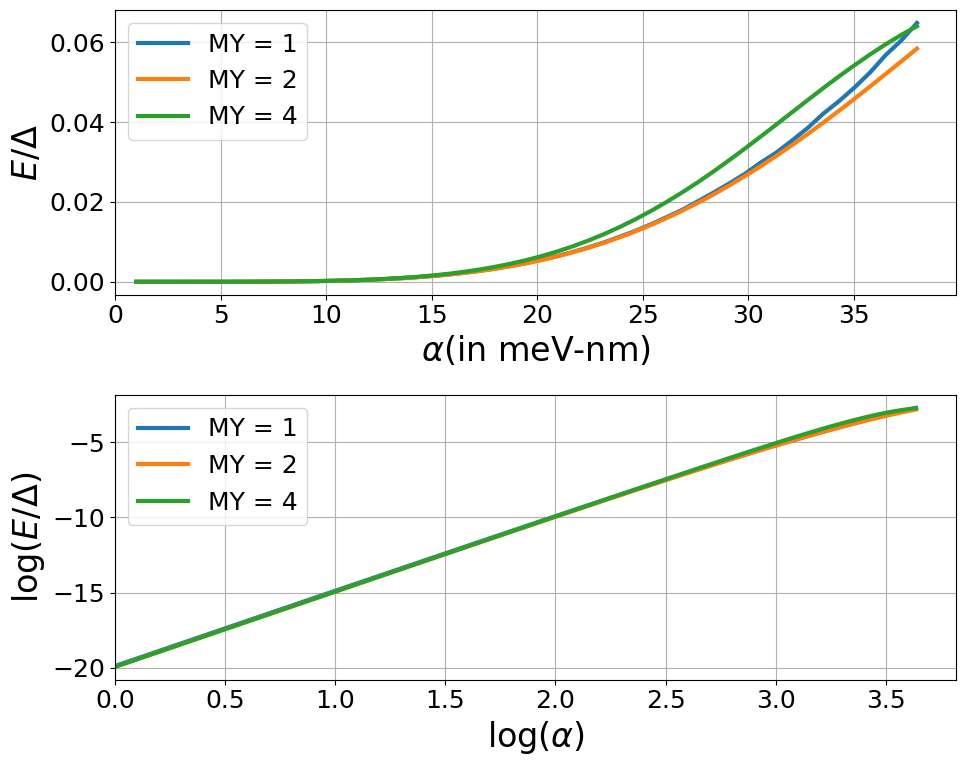

In [11]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

ALPHAT = np.linspace(1, 38, 51)

K=8

MY = np.array([1,2,4])      

plt.subplot(2,1,1)
#plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
for j in range(MY.shape[0]):
    plt.plot((ALPHAT), (Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label='MY = %i'%MY[j] )
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.legend()
plt.xlim(left=0)

plt.subplot(2,1,2)
for j in range(MY.shape[0]):
    plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label='MY = %i'%MY[j])
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.legend()
plt.xlim(left=0)
plt.grid(True)

plt.tight_layout()

plt.show()

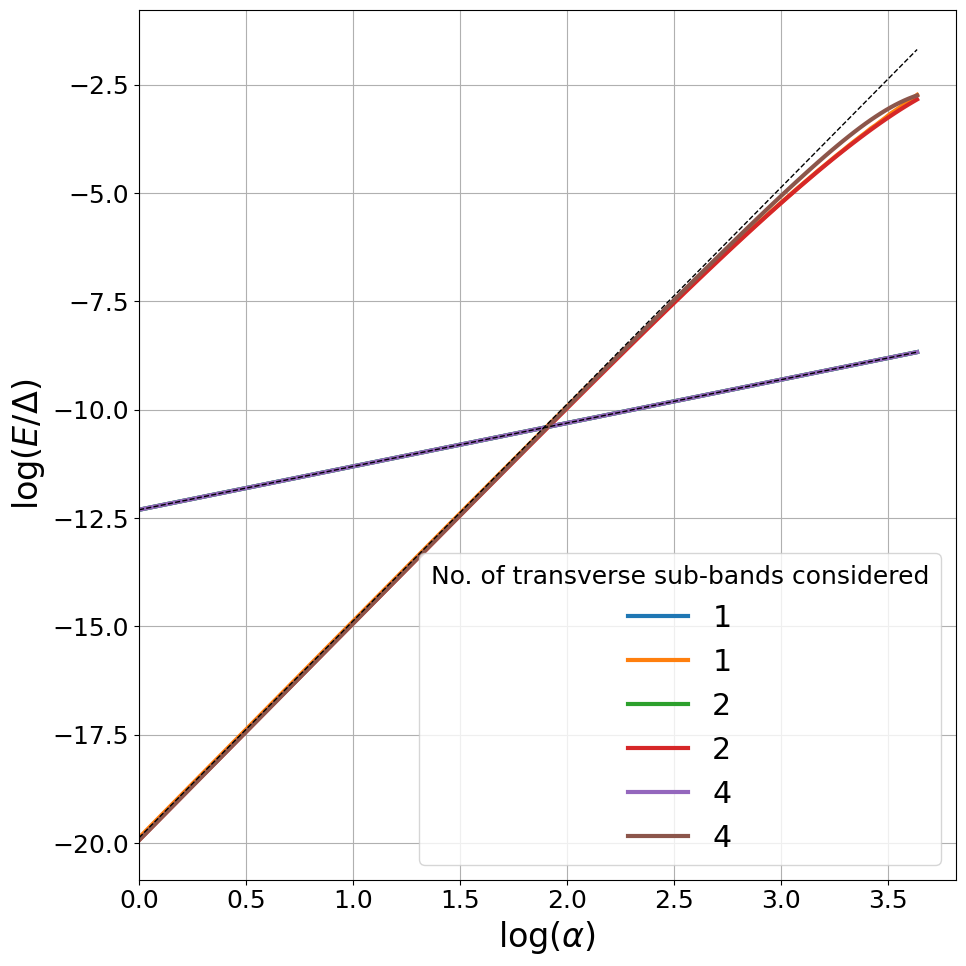

In [16]:
#ALPHAT_LI = np.linspace(1, 38, 51)

#MY_LI = np.array([1,2,4])  

ALPHAT = np.linspace(1, 38, 51)



plt.rc('font', size=18)

f = plt.figure(figsize=(10, 10))

Ep_Split_cu_minimal_model = Ep_cu_minimal_model[:,K//2+1,:] - Ep_cu_minimal_model[:,K//2,:]

plt.subplot(1,1,1)
for j in range(MY.shape[0]):

    plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu_minimal_model[:,j]/DELTA), lw=3, label='%i'%MY[j])
  
    plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label='%i'%MY[j])

plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu_minimal_model[0,0]/DELTA) + np.log(ALPHAT), linestyle='dashed', color='black', lw=1 )

plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[0,0]/DELTA) + 5*np.log(ALPHAT), linestyle='dashed', color='black', lw=1 )


plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)

# Adding a legend with a title
plt.legend(title='No. of transverse sub-bands considered', fontsize='large')
plt.xlim(left=0)
plt.grid(True)

plt.tight_layout()

plt.show()

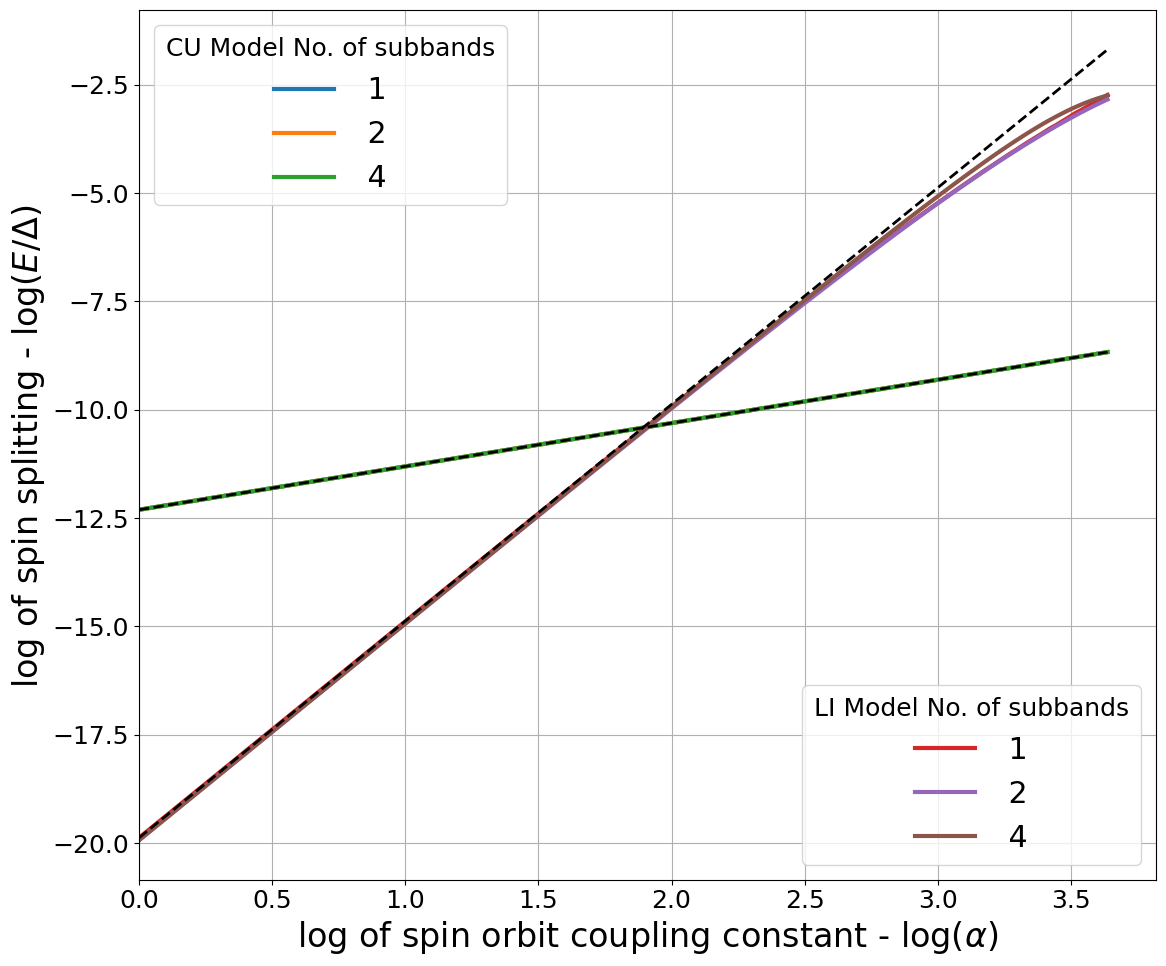

In [29]:


# Assuming ALPHA, MY, DELTA, Ep_cu_minimal_model, and Ep_Split_li_minimal_model are defined

plt.rc('font', size=18)
f = plt.figure(figsize=(12, 10))

# Assuming Ep_Split_cu_minimal_model calculation here
# Ep_Split_cu_minimal_model = Ep_cu_minimal_model[:,K//2+1,:] - Ep_cu_minimal_model[:,K//2,:]

plt.subplot(1,1,1)

# First group of plots for Ep_Split_cu_minimal_model
cu_handles = []  # To store handles for cu legends
for j in range(MY.shape[0]):
    h, = plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu_minimal_model[:,j]/DELTA), lw=3, label=f' {MY[j]}')
    cu_handles.append(h)

# Second group of plots for Ep_Split_li_minimal_model
li_handles = []  # To store handles for li legends
for j in range(MY.shape[0]):
    h, = plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label=f' {MY[j]}')
    li_handles.append(h)

# Reference lines, assuming they are related to cu_minimal_model for demonstration purposes
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu_minimal_model[0,0]/DELTA) + np.log(ALPHAT), linestyle='dashed', color='black', lw=2, label='Reference CU')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[0,0]/DELTA) + 5*np.log(ALPHAT), linestyle='dashed', color='black', lw=2, label='Reference LI')

#plt.xlabel(r'log($\alpha$)', fontsize=24)
#plt.ylabel(r'log($E/\Delta$)', fontsize=24)

plt.xlabel(r'log of spin orbit coupling constant - log($\alpha$)', fontsize=24)
plt.ylabel(r'log of spin splitting - log($E/\Delta$) ', fontsize=24)

# Creating two legends
# Add the first legend and use plt.gca().add_artist to keep it when adding the second legend
first_legend = plt.legend(handles=cu_handles, title='CU Model No. of subbands', fontsize='large', loc='upper left')
plt.gca().add_artist(first_legend)
# Add the second legend
plt.legend(handles=li_handles, title='LI Model No. of subbands', fontsize='large', loc='lower right')

plt.xlim(left=0)
plt.grid(True)
plt.tight_layout()
plt.show()


In [11]:
import sys
import os

notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393


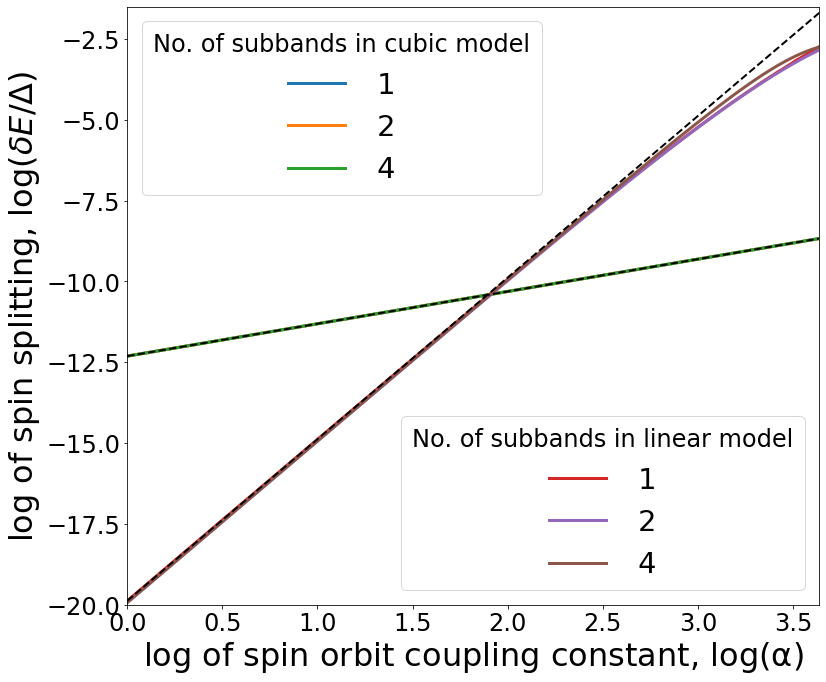

In [31]:
Ep_Split_cu_minimal_model = np.load('cubic_spin_Splitting_multisub.npy')
Ep_Split_li_minimal_model = np.load('linear_spin_Splitting_multisub.npy')

MY = np.array([1,2,4])              # no of subbands


ALPHAT = np.linspace(1, 38, 51)


NSM = 300          # in nm
#MY = np.array([1,2,4])              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

MU_const = 0.8 + OMEGA/2

# Assuming ALPHA, MY, DELTA, Ep_cu_minimal_model, and Ep_Split_li_minimal_model are defined

plt.rc('font', size=24)
f = plt.figure(figsize=(12, 10))

# Assuming Ep_Split_cu_minimal_model calculation here
# Ep_Split_cu_minimal_model = Ep_cu_minimal_model[:,K//2+1,:] - Ep_cu_minimal_model[:,K//2,:]

plt.subplot(1,1,1)

# First group of plots for Ep_Split_cu_minimal_model
cu_handles = []  # To store handles for cu legends
for j in range(MY.shape[0]):
    h, = plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu_minimal_model[:,j]/DELTA), lw=3, label=f' {MY[j]}')
    cu_handles.append(h)

# Second group of plots for Ep_Split_li_minimal_model
li_handles = []  # To store handles for li legends
for j in range(MY.shape[0]):
    h, = plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label=f' {MY[j]}')
    li_handles.append(h)

# Reference lines, assuming they are related to cu_minimal_model for demonstration purposes
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu_minimal_model[0,0]/DELTA) + np.log(ALPHAT), linestyle='dashed', color='black', lw=2, label='Reference CU')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[0,0]/DELTA) + 5*np.log(ALPHAT), linestyle='dashed', color='black', lw=2, label='Reference LI')

#plt.xlabel(r'log($\alpha$)', fontsize=24)
#plt.ylabel(r'log($E/\Delta$)', fontsize=24)

plt.xlabel(r'log of spin orbit coupling constant, log($\mathrm{\alpha}$)', fontsize=32)
plt.ylabel(r'log of spin splitting, log($\delta E/\mathrm{\Delta}$)', fontsize=32)

# Creating two legends
# Add the first legend and use plt.gca().add_artist to keep it when adding the second legend
first_legend = plt.legend(handles=cu_handles, title='No. of subbands in cubic model', fontsize='large', loc='upper left')
plt.gca().add_artist(first_legend)
# Add the second legend
plt.legend(handles=li_handles, title='No. of subbands in linear model', fontsize='large', loc='lower right')

plt.xlim(left=0, right=math.log(38))
plt.ylim(bottom=-20, top=-1.5)
#plt.grid(True)
plt.tight_layout()
plt.show()
